In [9]:
import pandas as pd
import numpy as np
import multiprocessing as mp
from Bio import SeqIO

# Sciarid database construction

## create braker hints file to run on galaxy for B. impatiens and L. ingenua

In [29]:
!wget https://bioinf.uni-greifswald.de/bioinf/partitioned_odb12/Arthropoda.fa.gz  
!gunzip Arthropoda.fa.gz  
!cat Arthropoda.fa  "ncbi_dataset/data/GCF_014529535.2/longest_isoform.fasta" > "proteins_for_braker.fa"

## download other sciarid genomes

In [19]:
%%bash
## downlaod B. odoriphaga 5/31/2026
curl -L -o ncbi_dataset.zip \
"https://api.ncbi.nlm.nih.gov/datasets/v2alpha/genome/accession/GCA_016920775.1/download?include_annotation_type=GENOME_GFF&include_annotation_type=GENOME_FASTA&include_annotation_type=PROT_FASTA&hydrated=FULLY_HYDRATED"

unzip -o ncbi_dataset.zip
rm ncbi_dataset.zip

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  116M    0  116M    0     0  53.0M      0 --:--:--  0:00:02 --:--:-- 53.0M


Archive:  ncbi_dataset.zip
  inflating: README.md               
  inflating: ncbi_dataset/data/assembly_data_report.jsonl  
  inflating: ncbi_dataset/data/GCA_016920775.1/GCA_016920775.1_B2019C_genomic.fna  
  inflating: ncbi_dataset/data/GCA_016920775.1/genomic.gff  
  inflating: ncbi_dataset/data/GCA_016920775.1/protein.faa  
  inflating: ncbi_dataset/data/dataset_catalog.json  
  inflating: md5sum.txt              


In [20]:
%%bash
## downlaod P.hygida 5/31/2026
curl -L -o ncbi_dataset.zip \
"https://api.ncbi.nlm.nih.gov/datasets/v2alpha/genome/accession/GCA_029228625.1/download?include_annotation_type=GENOME_GFF&include_annotation_type=GENOME_FASTA&include_annotation_type=PROT_FASTA&hydrated=FULLY_HYDRATED"

unzip -o ncbi_dataset.zip
rm ncbi_dataset.zip

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  192M    0  192M    0     0  5699k      0 --:--:--  0:00:34 --:--:-- 7112k


Archive:  ncbi_dataset.zip
  inflating: README.md               
  inflating: ncbi_dataset/data/assembly_data_report.jsonl  
  inflating: ncbi_dataset/data/GCA_029228625.1/GCA_029228625.1_FCFRP_Bhyg_1.0_genomic.fna  
  inflating: ncbi_dataset/data/GCA_029228625.1/genomic.gff  
  inflating: ncbi_dataset/data/GCA_029228625.1/protein.faa  
  inflating: ncbi_dataset/data/dataset_catalog.json  
  inflating: md5sum.txt              


In [8]:
%%bash
## downlaod B. impatiens GCA_965233325.1
curl -L -o ncbi_dataset.zip \
"https://api.ncbi.nlm.nih.gov/datasets/v2alpha/genome/accession/GCA_965233325.1/download?include_annotation_type=GENOME_GFF&include_annotation_type=GENOME_FASTA&include_annotation_type=PROT_FASTA&hydrated=FULLY_HYDRATED"

unzip -o ncbi_dataset.zip
rm ncbi_dataset.zip

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  114M    0  114M    0     0  59.6M      0 --:--:--  0:00:01 --:--:-- 59.6M


Archive:  ncbi_dataset.zip
  inflating: README.md               
  inflating: ncbi_dataset/data/assembly_data_report.jsonl  
  inflating: ncbi_dataset/data/GCA_965233325.1/GCA_965233325.1_idBraImpa2.1_genomic.fna  
  inflating: ncbi_dataset/data/dataset_catalog.json  
  inflating: md5sum.txt              


In [1]:
%%bash
## downlaod L. ingenua GCA_965233655.1
curl -L -o ncbi_dataset.zip \
"https://api.ncbi.nlm.nih.gov/datasets/v2alpha/genome/accession/GCA_965233655.1/download?include_annotation_type=GENOME_GFF&include_annotation_type=GENOME_FASTA&include_annotation_type=PROT_FASTA&hydrated=FULLY_HYDRATED"

unzip -o ncbi_dataset.zip
rm ncbi_dataset.zip

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 97.5M    0 97.5M    0     0  42.1M      0 --:--:--  0:00:02 --:--:-- 42.1M


Archive:  ncbi_dataset.zip
  inflating: README.md               
  inflating: ncbi_dataset/data/assembly_data_report.jsonl  
  inflating: ncbi_dataset/data/GCA_965233655.1/GCA_965233655.1_idLycInge5.1_genomic.fna  
  inflating: ncbi_dataset/data/dataset_catalog.json  
  inflating: md5sum.txt              


## process outputs of BRAKER3 annotation for L. ingenua and B. impatiens

In [6]:
!awk 'BEGIN{FS=OFS="\t"} {$1=substr($1,1,index($1,"_")-1)}1' "ncbi_dataset/data/GCA_965233655.1/Galaxy11-[BRAKER3 on dataset 2 and 4_ GTF Annotation].gtf" > "ncbi_dataset/data/GCA_965233655.1/braker.gtf"

In [2]:
!awk 'BEGIN{FS=OFS="\t"} {$1=substr($1,1,index($1,"_")-1)}1' "ncbi_dataset/data/GCA_965233325.1/Galaxy13-[BRAKER3 on dataset 1 and 2_ GTF Annotation].gtf" > "ncbi_dataset/data/GCA_965233325.1/braker.gtf"

In [7]:
!sbatch scripts/gffread.sh GCA_965233655.1


Submitted batch job 18813214


In [4]:
!sbatch scripts/gffread.sh GCA_965233325.1

Submitted batch job 18812981


In [11]:
from Bio import SeqIO


In [8]:
%%bash
sed -i 's/^>/>lingenua/' ncbi_dataset/data/GCA_965233655.1/protein.faa
sed -i 's/^>/>bimpatiens/' ncbi_dataset/data/GCA_965233325.1/protein.faa

In [9]:
from collections import defaultdict

def longest_iso(ac):
    input_file = open(f"ncbi_dataset/data/{ac}/protein.faa") 
    fasta = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
    ##exclude premature inframe stops
    fasta={x:fasta[x] for x in fasta if '.'  not in str(fasta[x].seq)}
    d=defaultdict(list)
    for x in fasta:
        d[x.split(".")[0]].append(x)
    longest_isos=[]
    for x in d:
        longest = max(d[x], key=lambda s: len(fasta[s]))
        longest_isos.append(longest)
    longest_isos={x:fasta[x] for x in longest_isos}
    
    SeqIO.write(
        longest_isos.values(),
        f"ncbi_dataset/data/{ac}/longest_isoform.faa",
        "fasta"
    )

In [12]:
longest_iso('GCA_965233655.1')
longest_iso('GCA_965233325.1')

In [86]:
from Bio import SeqIO
from collections import defaultdict

## Confirm a single isoform per gene 
input_file = open(f"ncbi_dataset/data/GCA_029228625.1/protein.faa") 
fasta = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
gff=pd.read_csv("ncbi_dataset/data/GCA_029228625.1/genomic.gff",sep="\t",comment="#",header=None)
cds=gff[gff[2]=='CDS']
gene_cds=defaultdict(set)
for index, row in cds.iterrows():
    x=row[8]
    gene_cds[x.split("locus_tag=")[1].split(';')[0]].add(x.split('ID=cds-')[1].split(';')[0])
max([len(gene_cds[x]) for x in gene_cds])

1

In [87]:
input_file = open(f"ncbi_dataset/data/GCA_016920775.1/protein.faa") 
fasta = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
gff=pd.read_csv("ncbi_dataset/data/GCA_016920775.1/genomic.gff",sep="\t",comment="#",header=None)
cds=gff[gff[2]=='CDS']
gene_cds=defaultdict(set)
for index, row in cds.iterrows():
    x=row[8]
    gene_cds[x.split("locus_tag=")[1].split(';')[0]].add(x.split('ID=cds-')[1].split(';')[0])
max([len(gene_cds[x]) for x in gene_cds])

1

In [101]:
input_file = open(f"ncbi_dataset/data/GCA_965233655.1/longest_isoform.faa") 
fasta = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
len(fasta)

35264

In [102]:
input_file = open(f"ncbi_dataset/data/GCA_965233325.1/longest_isoform.faa") 
fasta = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
len(fasta)

32751

In [164]:
!singularity exec /cvmfs/singularity.galaxyproject.org/c/d/cd-hit:4.8.1--hdbcaa40_2 cd-hit -i "ncbi_dataset/data/GCA_965233655.1/longest_isoform.faa" -o "ncbi_dataset/data/GCA_965233655.1/cdhit" -aL .90 -c .90

Program: CD-HIT, V4.8.1 (+OpenMP), May 20 2019, 02:33:49
Command: /usr/local/bin/cd-hit -i
         ncbi_dataset/data/GCA_965233655.1/longest_isoform.faa
         -o ncbi_dataset/data/GCA_965233655.1/cdhit -aL .90 -c
         .90

Started: Wed Jun  3 19:45:34 2026
                            Output                              
----------------------------------------------------------------
total seq: 35263
longest and shortest : 23773 and 13
Total letters: 15999758
Sequences have been sorted

Approximated minimal memory consumption:
Sequence        : 20M
Buffer          : 1 X 15M = 15M
Table           : 1 X 65M = 65M
Miscellaneous   : 0M
Total           : 102M

Table limit with the given memory limit:
Max number of representatives: 956465
Max number of word counting entries: 87130775

comparing sequences from          0  to      35263
..........    10000  finished       8878  clusters
..........    20000  finished      18061  clusters
..........    30000  finished      27183  cluster

In [165]:
!singularity exec /cvmfs/singularity.galaxyproject.org/c/d/cd-hit:4.8.1--hdbcaa40_2 cd-hit -i "ncbi_dataset/data/GCA_965233325.1/longest_isoform.faa" -o "ncbi_dataset/data/GCA_965233325.1/cdhit" -aL .90 -c .90

Program: CD-HIT, V4.8.1 (+OpenMP), May 20 2019, 02:33:49
Command: /usr/local/bin/cd-hit -i
         ncbi_dataset/data/GCA_965233325.1/longest_isoform.faa
         -o ncbi_dataset/data/GCA_965233325.1/cdhit -aL .90 -c
         .90

Started: Wed Jun  3 19:49:26 2026
                            Output                              
----------------------------------------------------------------
total seq: 32750
longest and shortest : 18775 and 11
Total letters: 15777674
Sequences have been sorted

Approximated minimal memory consumption:
Sequence        : 20M
Buffer          : 1 X 14M = 14M
Table           : 1 X 65M = 65M
Miscellaneous   : 0M
Total           : 101M

Table limit with the given memory limit:
Max number of representatives: 940634
Max number of word counting entries: 87334937

comparing sequences from          0  to      32750
..........    10000  finished       8736  clusters
..........    20000  finished      17665  clusters
..........    30000  finished      26617  cluster

In [13]:
%%bash
singularity exec /cvmfs/singularity.galaxyproject.org/b/u/busco:5.7.1--pyhdfd78af_0 busco -i ncbi_dataset/data/GCA_965233655.1/longest_isoform.faa -l ../Bradysia_coprophila/BUSCO_phylogenomics/BUSCO_phylogenomics/busco_downloads/lineages/diptera_odb10 -c 50 -m prot -f -o BUSCO/GCA_965233655.1_longest --offline 

2026-06-03 16:33:36 INFO:	***** Start a BUSCO v5.7.1 analysis, current time: 06/03/2026 16:33:36 *****
2026-06-03 16:33:36 INFO:	Configuring BUSCO with local environment
2026-06-03 16:33:36 INFO:	Running proteins mode
2026-06-03 16:33:36 INFO:	'Force' option selected; overwriting previous results directory
2026-06-03 16:34:09 INFO:	Input file is /net/bos-nfsisilon/ifs/rc_labs/extavour_lab/rkapoor/Bradysia_HGT_2026/ncbi_dataset/data/GCA_965233655.1/longest_isoform.faa
2026-06-03 16:34:09 INFO:	Using local lineages directory ../Bradysia_coprophila/BUSCO_phylogenomics/BUSCO_phylogenomics/busco_downloads/lineages/diptera_odb10
2026-06-03 16:34:13 INFO:	Running BUSCO using lineage dataset diptera_odb10 (eukaryota, 2024-01-08)
2026-06-03 16:34:13 INFO:	***** Run HMMER on gene sequences *****
2026-06-03 16:34:13 INFO:	Running 3285 job(s) on hmmsearch, starting at 06/03/2026 16:34:13
2026-06-03 16:34:24 INFO:	[hmmsearch]	329 of 3285 task(s) completed
2026-06-03 16:34:24 INFO:	[hmmsearch]	329 o

In [14]:
%%bash
singularity exec /cvmfs/singularity.galaxyproject.org/b/u/busco:5.7.1--pyhdfd78af_0 busco -i ncbi_dataset/data/GCA_965233325.1/longest_isoform.faa -l ../Bradysia_coprophila/BUSCO_phylogenomics/BUSCO_phylogenomics/busco_downloads/lineages/diptera_odb10 -c 50 -m prot -f -o BUSCO/GCA_965233325.1_longest --offline 

2026-06-03 16:36:13 INFO:	***** Start a BUSCO v5.7.1 analysis, current time: 06/03/2026 16:36:13 *****
2026-06-03 16:36:13 INFO:	Configuring BUSCO with local environment
2026-06-03 16:36:13 INFO:	Running proteins mode
2026-06-03 16:36:13 INFO:	'Force' option selected; overwriting previous results directory
2026-06-03 16:36:45 INFO:	Input file is /net/bos-nfsisilon/ifs/rc_labs/extavour_lab/rkapoor/Bradysia_HGT_2026/ncbi_dataset/data/GCA_965233325.1/longest_isoform.faa
2026-06-03 16:36:45 INFO:	Using local lineages directory ../Bradysia_coprophila/BUSCO_phylogenomics/BUSCO_phylogenomics/busco_downloads/lineages/diptera_odb10
2026-06-03 16:36:46 INFO:	Running BUSCO using lineage dataset diptera_odb10 (eukaryota, 2024-01-08)
2026-06-03 16:36:46 INFO:	***** Run HMMER on gene sequences *****
2026-06-03 16:36:46 INFO:	Running 3285 job(s) on hmmsearch, starting at 06/03/2026 16:36:46
2026-06-03 16:36:57 INFO:	[hmmsearch]	329 of 3285 task(s) completed
2026-06-03 16:37:02 INFO:	[hmmsearch]	657 o

In [12]:
%%bash
singularity exec /cvmfs/singularity.galaxyproject.org/b/u/busco:5.7.1--pyhdfd78af_0 busco -i ncbi_dataset/data/GCA_029228625.1/protein.faa -l ../Bradysia_coprophila/BUSCO_phylogenomics/BUSCO_phylogenomics/busco_downloads/lineages/diptera_odb10 -c 50 -m prot -f -o BUSCO/GCA_029228625.1 --offline 

2026-05-31 22:06:03 INFO:	***** Start a BUSCO v5.7.1 analysis, current time: 05/31/2026 22:06:03 *****
2026-05-31 22:06:03 INFO:	Configuring BUSCO with local environment
2026-05-31 22:06:03 INFO:	Running proteins mode
2026-05-31 22:06:03 INFO:	Input file is /net/bos-nfsisilon/ifs/rc_labs/extavour_lab/rkapoor/Bradysia_HGT_2026/ncbi_dataset/data/GCA_029228625.1/protein.faa
2026-05-31 22:06:03 INFO:	Using local lineages directory ../Bradysia_coprophila/BUSCO_phylogenomics/BUSCO_phylogenomics/busco_downloads/lineages/diptera_odb10
2026-05-31 22:06:04 INFO:	Running BUSCO using lineage dataset diptera_odb10 (eukaryota, 2024-01-08)
2026-05-31 22:06:04 INFO:	***** Run HMMER on gene sequences *****
2026-05-31 22:06:04 INFO:	Running 3285 job(s) on hmmsearch, starting at 05/31/2026 22:06:04
2026-05-31 22:06:11 INFO:	[hmmsearch]	329 of 3285 task(s) completed
2026-05-31 22:06:14 INFO:	[hmmsearch]	657 of 3285 task(s) completed
2026-05-31 22:06:17 INFO:	[hmmsearch]	986 of 3285 task(s) completed
2026-

In [11]:
%%bash
singularity exec /cvmfs/singularity.galaxyproject.org/b/u/busco:5.7.1--pyhdfd78af_0 busco -i ncbi_dataset/data/GCA_016920775.1/protein.faa -l ../Bradysia_coprophila/BUSCO_phylogenomics/BUSCO_phylogenomics/busco_downloads/lineages/diptera_odb10 -c 50 -m prot -f -o BUSCO/GCA_016920775.1 --offline 

2026-05-31 22:02:15 INFO:	***** Start a BUSCO v5.7.1 analysis, current time: 05/31/2026 22:02:15 *****
2026-05-31 22:02:15 INFO:	Configuring BUSCO with local environment
2026-05-31 22:02:15 INFO:	Running proteins mode
2026-05-31 22:02:15 INFO:	'Force' option selected; overwriting previous results directory
2026-05-31 22:02:15 INFO:	Input file is /net/bos-nfsisilon/ifs/rc_labs/extavour_lab/rkapoor/Bradysia_HGT_2026/ncbi_dataset/data/GCA_016920775.1/protein.faa
2026-05-31 22:02:16 INFO:	Using local lineages directory ../Bradysia_coprophila/BUSCO_phylogenomics/BUSCO_phylogenomics/busco_downloads/lineages/diptera_odb10
2026-05-31 22:02:19 INFO:	Running BUSCO using lineage dataset diptera_odb10 (eukaryota, 2024-01-08)
2026-05-31 22:02:19 INFO:	***** Run HMMER on gene sequences *****
2026-05-31 22:02:19 INFO:	Running 3285 job(s) on hmmsearch, starting at 05/31/2026 22:02:19
2026-05-31 22:02:26 INFO:	[hmmsearch]	329 of 3285 task(s) completed
2026-05-31 22:02:29 INFO:	[hmmsearch]	657 of 3285 t

In [171]:
%%bash
cat \
ncbi_dataset/data/GCA_029228625.1/protein.faa \
ncbi_dataset/data/GCA_016920775.1/protein.faa \
"ncbi_dataset/data/GCA_965233655.1/cdhit" \
"ncbi_dataset/data/GCA_965233325.1/cdhit" \
"ncbi_dataset/data/GCF_014529535.2/longest_isoform.fasta" \
> combined_sciarid.fa

In [2]:

input_file = open(f"combined_sciarid.fa") 
fasta = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
len(fasta)

111399

In [172]:
%%bash
mkdir $SCRATCH/extavour_lab/Everyone/Rishabh/combined_sciarid
singularity exec /cvmfs/singularity.galaxyproject.org/d/i/diamond:2.2.0--he361c42_0 diamond makedb --in combined_sciarid.fa -d $SCRATCH/extavour_lab/Everyone/Rishabh/combined_sciarid

mkdir: cannot create directory ‘/n/netscratch/extavour_lab/Everyone/Rishabh/combined_sciarid’: File exists
diamond v2.2.0.180 (C) Max Planck Society for the Advancement of Science, Benjamin J. Buchfink, University of Tuebingen
Documentation, support and updates available at http://www.diamondsearch.org
Please cite: http://dx.doi.org/10.1038/s41592-021-01101-x Nature Methods (2021)

#CPU threads: 112
Scoring parameters: (Matrix=BLOSUM62 Lambda=0.267 K=0.041 Penalties=11/1)
Database input file: combined_sciarid.fa
Opening the database file...  [0.095s]
Loading sequences...  [0.878s]
Masking sequences...  [0.162s]
Writing sequences...  [0.03s]
Hashing sequences...  [0.013s]
Loading sequences...  [0s]
Writing trailer...  [0.002s]
Closing the input file...  [0s]
Closing the database file...  [0.107s]

Database sequences  111399
  Database letters  52685541
     Database hash  50a4232f0e66e7573577f5720bd0905d
        Total time  1.291000s


In [173]:
!sh scripts/diamond_sciarid.sh

diamond v2.2.0.180 (C) Max Planck Society for the Advancement of Science, Benjamin J. Buchfink, University of Tuebingen
Documentation, support and updates available at http://www.diamondsearch.org
Please cite: http://dx.doi.org/10.1038/s41592-021-01101-x Nature Methods (2021)

#CPU threads: 110
Scoring parameters: (Matrix=BLOSUM62 Lambda=0.267 K=0.041 Penalties=11/1)
Temporary directory: /n/netscratch/extavour_lab/Everyone/Rishabh
#Target sequences to report alignments for: 2000
Opening the database...  [0.065s]
Database: /n/netscratch/extavour_lab/Everyone/Rishabh/combined_sciarid (type: Diamond database, sequences: 111399, letters: 52685541)
Block size = 400000000
Opening the input file...  [0.009s]
Opening the output file...  [0.003s]
Loading query sequences...  [0.003s]
Loaded 929021 bytes from disk at 266.702 MB/s
Masking queries...  [0.159s]
Algorithm: Double-indexed
Building query histograms...  [0.006s]
Seeking in database...  [0s]
Loading reference sequences...  [0.073s]
Maski

In [9]:

cols= "qseqid sseqid stitle pident length mismatch gapopen qstart qend sstart send evalue bitscore qcovhsp".split(" ")
df_sciar=pd.read_csv("/n/netscratch/extavour_lab/Everyone/Rishabh/sciarid_diamond_htg_search",sep="\t", names=cols)


conditions = [
    df_sciar['sseqid'].str.contains('XP_', na=False),
    df_sciar['sseqid'].str.contains('lingenua', na=False),
    df_sciar['sseqid'].str.contains('bimpatiens', na=False),
    df_sciar['sseqid'].str.contains('KAJ', na=False),
    df_sciar['sseqid'].str.contains('KAG', na=False),
]

choices = [
    'Bradysia coprophila',
    'Lycoriella ingenua',
    'Bradysia impatiens',
    'Pseudolycoriella hygida',
    'Bradysia odoriphaga'
]

df_sciar['species'] = np.select(conditions, choices, default=df_sciar.get('species', np.nan))

In [80]:
df_sciar.to_csv("outputs/sciarid_diamond_search.tsv",sep="\t")

In [13]:
df_sciar=pd.read_csv("outputs/sciarid_diamond_search.tsv",sep="\t",index_col=0)


In [14]:

alldf=pd.read_csv("outputs/per_protein_diamond_data.tsv",sep="\t",index_col=0)
dipt_proteins=set(alldf[alldf.slineage.astype(str).str.contains('Diptera')]['accession'])
htgdf=alldf[alldf.HGT]
htgdf=htgdf.set_index('accession')
htgs=set(htgdf.index)


In [15]:

def calculate_overlap_percentage(interval1, interval2):
    # Calculate the overlap
    overlap_start = max(interval1[0], interval2[0])
    overlap_end = min(interval1[1], interval2[1])
    
    overlap_length = max(0, overlap_end - overlap_start)
    
    # Calculate the length of the second interval
    interval2_length = interval2[1] - interval2[0]
    
    # Calculate the percentage overlap
    overlap_percentage = (overlap_length / interval2_length) * 100
    
    return overlap_percentage

In [15]:
adj_list={}
for index, row in htgdf.iterrows():
    
    non_sc_bit=row.bitscore
    start,stop=row.qstart,row.qend
    
    dfb=df_sciar[(df_sciar.qseqid==index)&(df_sciar.sseqid.isin(set(htgdf.index)))&(df_sciar.evalue<1e-10)&(df_sciar.bitscore>.80*non_sc_bit)].copy()
    for index2, row2 in dfb.iterrows():
        starti,stopi=row2.qstart,row2.qend
        dfb.loc[index2,'overlap_top_nsc']=calculate_overlap_percentage((starti,stopi), (start,stop))
    dfb=dfb[dfb['overlap_top_nsc']>30]
    adj_list[index]=list(set(dfb.sseqid))
import networkx as nx

def find_connected_components(adj_list):
    graph = nx.DiGraph(adj_list)
    return list(nx.weakly_connected_components(graph))

connected_components = find_connected_components(adj_list)
connected_components={i:connected_components[i] for i in list(range(len(connected_components)))}

len(connected_components)

924

In [10]:
representative={}
import pickle
for i in connected_components:
    l=list(connected_components[i])
    x=l[np.argmax([htgdf.loc[x,"length"] for x in l])]
    representative[i]=x
with open('outputs/connected_components_reps.pickle', 'wb') as f:
    pickle.dump(representative, f)
with open('outputs/connected_components.pickle', 'wb') as f:
    pickle.dump(connected_components, f)

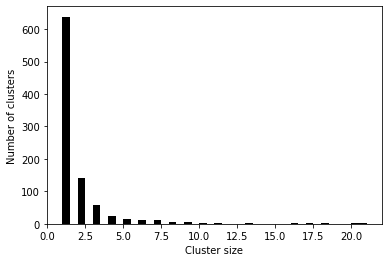

In [11]:
import matplotlib.pyplot as plt
lens=[len(x) for x in connected_components.values()]
plt.hist(lens,color='black',bins=40)
plt.xlabel("Cluster size")
plt.ylabel("Number of clusters")
plt.show()

In [8]:
sciar_orthos={}
for index, row in htgdf.iterrows():
    
    non_sc_bit=row.bitscore
    start,stop=row.qstart,row.qend


    
    dfb=df_sciar[(df_sciar.qseqid==index)&(df_sciar.evalue<1e-10)&(df_sciar.bitscore>.80*non_sc_bit)&(df_sciar.species!='Bradysia coprophila')].copy()
    if dfb.shape[0]>0:
        for index2, row2 in dfb.iterrows():
            starti,stopi=row2.qstart,row2.qend
            dfb.loc[index2,'overlap_top_nsc']=calculate_overlap_percentage((starti,stopi), (start,stop))
        dfb=dfb[dfb['overlap_top_nsc']>30]
        dfb = (
                dfb.sort_values(['species', 'evalue'], ascending=[True, True])
                   .groupby('species', group_keys=False)
                   .head(15)
            )
        sciar_orthos[index]=list(set(dfb.sseqid))



In [8]:
input_file = open("combined_sciarid.fa") 
fasta_sciarid = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))

In [9]:
##uses blastdbcmdb to append protein with accession "e" to fasta with path "o"
def query_nr(x):
    e,o=x
    !sh scripts/query_clustered_nr_protein.sh $e $o

In [10]:
def get_sciar_species(x):
    if 'XP_' in x:
        return 'Bradysia coprophila'
    elif 'lingenua' in x:
        return 'Lycoriella ingenua'
    elif 'bimpatiens' in x:
        return 'Bradysia impatiens'
    elif 'KAJ' in x:
        return 'Pseudolycoriella hygida'
    elif 'KAG' in x:
        return 'Bradysia odoriphaga'
sciarid_linmap={'Bradysia coprophila': 'cellular organisms; Eukaryota; Opisthokonta; Metazoa; Eumetazoa; Bilateria; Protostomia; Ecdysozoa; Panarthropoda; Arthropoda; Mandibulata; Pancrustacea; Altocrustacea; Allotriocarida; Hexapoda; Insecta; Dicondylia; Pterygota; Neoptera; Eumetabola; Endopterygota; Aparaglossata; Panorpida; Diptera; Nematocera; Bibionomorpha; Sciaroidea; Sciaridae; Bradysia; Bradysia coprophila',
 'Bradysia odoriphaga': 'cellular organisms; Eukaryota; Opisthokonta; Metazoa; Eumetazoa; Bilateria; Protostomia; Ecdysozoa; Panarthropoda; Arthropoda; Mandibulata; Pancrustacea; Altocrustacea; Allotriocarida; Hexapoda; Insecta; Dicondylia; Pterygota; Neoptera; Eumetabola; Endopterygota; Aparaglossata; Panorpida; Diptera; Nematocera; Bibionomorpha; Sciaroidea; Sciaridae; Bradysia; Bradysia odoriphaga',
 'Bradysia impatiens': 'cellular organisms; Eukaryota; Opisthokonta; Metazoa; Eumetazoa; Bilateria; Protostomia; Ecdysozoa; Panarthropoda; Arthropoda; Mandibulata; Pancrustacea; Altocrustacea; Allotriocarida; Hexapoda; Insecta; Dicondylia; Pterygota; Neoptera; Eumetabola; Endopterygota; Aparaglossata; Panorpida; Diptera; Nematocera; Bibionomorpha; Sciaroidea; Sciaridae; Bradysia; Bradysia impatiens',
 'Lycoriella ingenua': 'cellular organisms; Eukaryota; Opisthokonta; Metazoa; Eumetazoa; Bilateria; Protostomia; Ecdysozoa; Panarthropoda; Arthropoda; Mandibulata; Pancrustacea; Altocrustacea; Allotriocarida; Hexapoda; Insecta; Dicondylia; Pterygota; Neoptera; Eumetabola; Endopterygota; Aparaglossata; Panorpida; Diptera; Nematocera; Bibionomorpha; Sciaroidea; Sciaridae; Lycoriella; Lycoriella ingenua',
 'Pseudolycoriella hygida': 'cellular organisms; Eukaryota; Opisthokonta; Metazoa; Eumetazoa; Bilateria; Protostomia; Ecdysozoa; Panarthropoda; Arthropoda; Mandibulata; Pancrustacea; Altocrustacea; Allotriocarida; Hexapoda; Insecta; Dicondylia; Pterygota; Neoptera; Eumetabola; Endopterygota; Aparaglossata; Panorpida; Diptera; Nematocera; Bibionomorpha; Sciaroidea; Sciaridae; Pseudolycoriella; Pseudolycoriella hygida'}

In [5]:
import pickle
with open('outputs/connected_components.pickle', 'rb') as f:
    connected_components = pickle.load(f)
with open('outputs/connected_components_reps.pickle', 'rb') as f:
    representative = pickle.load(f)

In [17]:

def write(i):
    phylo_dict={}
    !mkdir -p "outputs/phylogenetic_dataset/"$i
    x=representative[i]
    df=pd.read_csv(f"/n/netscratch/extavour_lab/Everyone/Rishabh/diamond_clustered_results_split_edited/{x}.tsv",sep="\t",index_col=0, nrows=2000)
    ##exclude synthetic taxid
    df=df[df.staxids.astype(int)!=32630]
    ## exclude rhagoletis zephyria
    df=df[df.staxids.astype(int)!=28612]
    df=df[df.evalue<1e-3]
    start,stop=htgdf.loc[x,['qstart','qend']]    
    df['overlap_top_nsc'] = [
        calculate_overlap_percentage((s, e), (start, stop))
        for s, e in zip(df['qstart'], df['qend'])
    ]
    df=df[df['overlap_top_nsc']>30]
    df=df.loc[df.groupby('sseqid')['evalue'].idxmin()].sort_values('evalue')
    
    ## add top 30 non-sciarid dipteran proteins
    dipt=set(df[~df.slineage.str.contains('Sciaridae')&df.slineage.str.contains('Diptera')].iloc[0:30].sseqid)
    
    ##add top 300 non-dipteran proteins, ensuring up to 20 non-metazoan and 20 metazoan representives
    non_dipt=set(df[~df.slineage.str.contains('Diptera')].iloc[0:300,:].sseqid)
    non_dipt=non_dipt|set(df[~(df.slineage.str.contains('Diptera'))&(df.slineage.str.contains('Metazoa'))].iloc[0:20,:].sseqid)
    non_dipt=non_dipt|set(df[~(df.slineage.str.contains('Metazoa'))].iloc[0:20,:].sseqid)
   
    td=dipt|non_dipt

    pool = mp.Pool(processes=90)
    
    for index, row in df[df.sseqid.isin(td)].iterrows():
        phylo_dict[row.sseqid]=row.slineage

        
    result = pool.map(query_nr, [(xt, f"outputs/phylogenetic_dataset/{i}/seqs.fasta") for xt in td])
    

    ## add dipteran ancestry bradysia proteins
    dfb=df_sciar[df_sciar.sseqid.isin(dipt_proteins)&(df_sciar.qseqid==x)&(df_sciar.evalue<1e-10)].copy()
    dfb['overlap_top_nsc'] = [
        calculate_overlap_percentage((s, e), (start, stop))
        for s, e in zip(dfb['qstart'], dfb['qend'])
    ]
    bradysia_dipt=set()
    ##write top bradysia dipteran hit and its relatives 
    if dfb[dfb.overlap_top_nsc>30].shape[0]>0:
        bradysia_dipt=dfb[dfb.overlap_top_nsc>30].iloc[0,:].sseqid
        
        df=pd.read_csv(f"/n/netscratch/extavour_lab/Everyone/Rishabh/diamond_clustered_results_split_edited/{bradysia_dipt}.tsv",sep="\t",index_col=0, nrows=2000)
        
        df=df.loc[df.groupby('sseqid')['evalue'].idxmin()].sort_values('evalue')
        df=df[df.evalue<1e-10]
        td=list(df[~df.slineage.str.contains('Sciaridae')&df.slineage.str.contains('Diptera')].iloc[0:10,:].sseqid.values)
        td2=list(df[~df.slineage.str.contains('Diptera')&df.slineage.str.contains('Arthropoda')].iloc[0:10,:].sseqid.values)
        
        td.extend(td2)
        td=set(td)-dipt-non_dipt
        result = pool.map(query_nr, [(xt, f"outputs/phylogenetic_dataset/{i}/seqs.fasta") for xt in td])
        pool.close()
        for index, row in df[df.sseqid.isin(td)].iterrows():
            phylo_dict[row.sseqid]=row.slineage
        bradysia_dipt=set(dfb[dfb.overlap_top_nsc>30].iloc[0:5,:].sseqid)
    ##add bradysia htgs
    dfb=df_sciar[df_sciar.sseqid.isin(htgdf.index)&(df_sciar.qseqid==x)&(df_sciar.evalue<1e-10)].copy()
    dfb['overlap_top_nsc'] = [
        calculate_overlap_percentage((s, e), (start, stop))
        for s, e in zip(dfb['qstart'], dfb['qend'])
    ]
    bradysia_htg=set(dfb[dfb.overlap_top_nsc>30].sseqid)|connected_components[i]
    
    ##add other sciarid proteins, sciarid hits of all cluster sequences
    sciar=set()
    c=connected_components[i]
    cl=[set(sciar_orthos[cx]) for cx in c if cx in sciar_orthos]
    if len(cl)>0:
       sciar = set.union(*cl)

    td= bradysia_htg|sciar|bradysia_dipt

    

        
    for seq in td:
        species=get_sciar_species(seq)
        phylo_dict[seq]=sciarid_linmap[species]

    f=open(f"outputs/phylogenetic_dataset/{i}/seqs.fasta","a")
    for s in td:
        f.write(f">{s}\n")
        f.write(str(fasta_sciarid[s].seq)+"\n")
    f.close()

    input_file = open(f"outputs/phylogenetic_dataset/{i}/seqs.fasta")

    fastaj = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
    
    tw=[x for x in fastaj if len(fastaj[x])<5000]
    
    output_file = f"outputs/phylogenetic_dataset/{i}/seqs.fasta"
    if len(tw)>3:
        with open(output_file, "w") as out_f:
            SeqIO.write([fastaj[x] for x in tw], out_f, "fasta")
        with open(f"outputs/phylogenetic_dataset/{i}/phylo_dict.pkl", "wb") as f:
            pickle.dump(phylo_dict, f)
    else:
        print(i,"too few sequences")

In [23]:
for i in representative:
    write(i)
    !sbatch scripts/run_phylopipe.sh "$i"

Error: [blastdbcmd] Error: oid headers do not contain target gi/seq_id.
Submitted batch job 19695645
Error: [blastdbcmd] Error: oid headers do not contain target gi/seq_id.
Error: [blastdbcmd] Error: oid headers do not contain target gi/seq_id.
Submitted batch job 19695688
Submitted batch job 19695771
Submitted batch job 19695810
Submitted batch job 19695830
Submitted batch job 19695863
Submitted batch job 19695884
Submitted batch job 19695921
Submitted batch job 19695923
Submitted batch job 19695940
Submitted batch job 19696031
Error: [blastdbcmd] Error: oid headers do not contain target gi/seq_id.
Submitted batch job 19696079
Error: [blastdbcmd] Error: oid headers do not contain target gi/seq_id.
Error: [blastdbcmd] Error: oid headers do not contain target gi/seq_id.
Submitted batch job 19696135
Submitted batch job 19696162
Submitted batch job 19696341
Submitted batch job 19696356
Submitted batch job 19696500
Submitted batch job 19696615
Submitted batch job 19696750
Error: [blastdbcm

In [2]:
import matplotlib.colors as mcolors
import itolapi
from itolapi import Itol
import os
from pathlib import Path
import sys
colors=["blue","cyan","brown","green","teal","pink","orange","black","red","yellow","fuchsia"]
cmaphex={c:mcolors.to_hex(c) for c in colors}

def get_color(l):
  
  
    if  'Bacteria' in str(l):
        return 'blue'
    elif 'Viruses' in str(l):
        return 'cyan'
    elif 'kingdom' in set(l.keys()) and 'Viridiplantae' in str(l['kingdom']):
        return 'green'
    elif 'kingdom' in set(l.keys()) and 'Fungi' in str(l['kingdom']):
        return 'brown'
    elif 'species' in set(l.keys()) and 'Bradysia coprophila' in str(l['species']):
        return 'red'
    elif 'family' in set(l.keys()) and  'Sciaridae' in str(l['family']):
        return 'fuchsia'
    elif 'order' in set(l.keys()) and 'Diptera' in str(l['order'])=='Diptera':
        return 'pink'
    elif 'class' in set(l.keys()) and  'Insecta' in str(l['class']):
        return 'orange'
    elif 'kingdom' in set(l.keys()) and 'Metazoa' in str(l['kingdom']):
        return 'yellow'
    else:
        return 'black'

In [11]:
from ete3 import NCBITaxa
from ete3 import Tree
from Bio import SeqIO
import pandas as pd

ncbi = NCBITaxa()

TEMPLATE_DIR = "./datasets"


def lineage_string_to_ranks(slineage):
    names = [x.strip() for x in str(slineage).split(";") if x.strip()]

    name2taxids = ncbi.get_name_translator(names)

    taxids = [
        name2taxids[name][0]
        for name in names
        if name in name2taxids
    ]

    taxid2rank = ncbi.get_rank(taxids)
    taxid2name = ncbi.get_taxid_translator(taxids)

    return {
        rank: taxid2name[taxid]
        for taxid, rank in taxid2rank.items()
    }


def ensure_rank_dict(x):
    if isinstance(x, dict):
        return x
    return lineage_string_to_ranks(x)


def copy_template(fout, template_name):
    with open(f"{TEMPLATE_DIR}/{template_name}", "r") as ftemplate:
        for line in ftemplate:
            fout.write(line)

from pathlib import Path
def upload_prep(i):

    directory = Path(f"outputs/phylogenetic_dataset/{i}/")
    
    for file in directory.glob("*.txt"):
        file.unlink()
    xi = representative[i]

    t = Tree(f"outputs/phylogenetic_dataset/{i}/rev_aa.treefile")
    
    dfi = pd.read_csv(
        f"/n/netscratch/extavour_lab/Everyone/Rishabh/diamond_clustered_results_split_edited/{xi}.tsv",
        sep="\t"
    )


    with open(f"outputs/phylogenetic_dataset/{i}/trimAl_MSA_sub_seq.fasta") as input_file:
        fastaj = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
    with open(f"outputs/phylogenetic_dataset/{i}/MSA.fasta") as input_file:
        fastao = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))

    dfi = dfi.set_index("sseqid")
    ldict={}
    with open(f"outputs/phylogenetic_dataset/{i}/phylo_dict.pkl", "rb") as f:
        ldictog = pickle.load(f)
    
    tdn=[x for x in ldictog]
    td=[ldictog[x] for x in ldictog] 
    ncbi = None

    def init_worker():
        global ncbi
        ncbi = NCBITaxa()
    with mp.Pool(processes=19, initializer=init_worker) as pool:
        results = pool.map(lineage_string_to_ranks, td)

    ldict={x:y for x,y in zip(tdn,results)}
    
    df_sciar_ids = set(df_sciar.sseqid)

    cmap = {
        x: get_color(ldict[x])
        for x in ldict
    }

    with open(f"outputs/phylogenetic_dataset/{i}/colorstrip.txt", "w") as f:
        copy_template(f, "color_strip_dataset.txt")

        for index in cmap:
            f.write(index + " " + cmaphex[cmap[index]] + "\n")

        if xi not in cmap:
            f.write(xi + " " + cmaphex["red"] + "\n")

    cc=connected_components[i]
    with open(f"outputs/phylogenetic_dataset/{i}/color_strip_htg.txt", "w") as f:
        copy_template(f, "color_strip_htg.txt")

        for x in t:
            if x.name in cc:
                f.write(x.name + " " + '#FF0000' + "\n")
            elif x.name in htgs:
                f.write(x.name + " " + '#FFFF00' + "\n")
    

    with open(f"outputs/phylogenetic_dataset/{i}/des_labels.txt", "w") as f:
        copy_template(f, "des_label_template.txt")

        for s in fastaj:
            d = fastao[s].description.replace(",", "_")
            if s in fasta_sciarid:
                 d=fasta_sciarid[s].description.replace(",", "_")
            f.write(s + "," + d + ",-1,#000000,normal,1,0\n")

    with open(f"outputs/phylogenetic_dataset/{i}/labels.txt", "w") as f:
        copy_template(f, "partial_lineage.txt")      
        for index in ldict:
    
            species = ldictog[index].split(";")[-1].strip()
    
            phylum = ldict[index].get("phylum", "NA")
            taxclass = ldict[index].get("class", "NA")
            order = ldict[index].get("order", "NA")
    
            label = (
                f"{species}_{phylum}_{taxclass}_{order}"
                .replace(",", "_")
            )
    
            f.write(
                f"{index},{label},-1,#000000,normal,1,0\n"
            )


    with open(f"outputs/phylogenetic_dataset/{i}/full_lineage_labels.txt", "w") as f:
        copy_template(f, "full_lineage.txt")

        for x in ldict:
            lstr = ldictog[x].replace(",", "_").replace("' ", "").replace(" ", " '").replace("[", "").replace("]", "").replace("'", "").replace("_ ", "_")

            f.write(x + ",_" + lstr + ",-1,#000000,normal,1,0\n")

    with open(f"outputs/phylogenetic_dataset/{i}/species_labels.txt", "w") as f:
        copy_template(f, "species_template.txt")

        for x in ldict:
            if "species" in ldict[x]:
                sciname = ldict[x]["species"]
                f.write(x + "," + sciname.replace(",", "_") + ",-1,#000000,normal,1,0\n")
            elif x in dfi.index:
                f.write(x + "," + str(dfi.loc[x, "sscinames"]).replace(",", "_") + ",-1,#000000,normal,1,0\n")

   

In [12]:

def colorstrip_htg(i):
    t = Tree(f"outputs/phylogenetic_dataset/{i}/rev_aa.treefile")
    cc=connected_components[i]
    with open(f"outputs/phylogenetic_dataset/{i}/color_strip_htg.txt", "w") as f:
        copy_template(f, "color_strip_htg.txt")

        for x in t:
            if x.name in cc:
                f.write(x.name + " " + '#FF0000' + "\n")
            elif x.name in htgs:
                f.write(x.name + " " + '#FFFF00' + "\n")
    

In [ ]:
for i in representative:
    !sh scripts/run_phylopipe.sh "$i"

In [3]:
def upload(n,project,workspace):
    # try:
    test = Itol()
    n=str(n)
    current_dir = Path(os.path.realpath(f"outputs/phylogenetic_dataset/{n}/colorstrip.txt")).parent
    tree = current_dir/"rev_aa_midpoint.treefile"
    test.add_file(tree)



    test.add_file(current_dir / 'colorstrip.txt')
    test.add_file(current_dir / 'color_strip_htg.txt')
    test.add_file(current_dir / 'full_lineage_labels.txt')
    test.add_file(current_dir / 'species_labels.txt')
    test.add_file(current_dir / 'des_labels.txt')
    test.add_file(current_dir / 'labels.txt')
    # Add parameters

    test.params['APIkey'] = 'xZMZCofEGnKYSfuydC0PaQ'
    test.params['treeName'] = "ML_tree_"+n+"."
    test.params['projectName'] = project
    test.params['workspaceName'] = workspace

    # Submit the tree
    good_upload = test.upload()
    if not good_upload:
        print('There was an error:' + test.comm.upload_output)
        sys.exit(1)
    else:
        f=open("good_uploads_7_28.txt","a")
        f.write(n)
        f.write("/n")
        f.close()
    # except:
    #     print(n)

In [1]:
from pathlib import Path
from ete3 import Tree


def midpoint_root_newick(tree_path):
    """
    Read a Newick tree from `tree_path`, midpoint-root it using ete3,
    write it to a new file with '_midpoint' appended to the input stem,
    and return the output path.

    Example:
        input:  trees/example.nwk
        output: trees/example_midpoint.nwk
    """
    tree_path = Path(tree_path)

    tree = Tree(str(tree_path), format=1)

    midpoint = tree.get_midpoint_outgroup()
    tree.set_outgroup(midpoint)

    out_path = tree_path.with_name(f"{tree_path.stem}_midpoint{tree_path.suffix}")

    tree.write(outfile=str(out_path), format=1)

    return str(out_path)

/n/home11/rkapoor/.conda/envs/rishabh/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [4]:
import os
td=[]
for i in os.listdir("outputs/phylogenetic_dataset"):
    if 'rev_aa.contree' in os.listdir(f"outputs/phylogenetic_dataset/{i}"):
        td.append(i)
for x in td:
    x=int(x)
    midpoint_root_newick(f"outputs/phylogenetic_dataset/{x}/rev_aa.treefile")
    upload_prep(x)


In [5]:
len(td)

918

In [7]:
for x in td:
   x=int(x)
   upload(x,'Bradysia_HGT_ML_Gene_Trees','Bradysia_HGT_2026')

In [8]:
%%bash
tar -czf outputs/phylogenetic_dataset.tar.gz -C "./outputs/" "phylogenetic_dataset"